<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Reranking cannot recover a passage it never receives

Start with a small, deliberately imperfect candidate order, score only its top-K prefix with a local cross-encoder, and retain the two highest-scoring usable passages. Then widen K to admit a password-reset answer that was previously excluded.

**All candidate passages and their initial order are invented.** This notebook demonstrates the boundary between candidate selection and reranking; it does not claim to implement or benchmark BM25, vector search, or a production recall system. The author’s “direct answer” label identifies the planted passage for this exercise. No text is sent to a model service: inference uses the real local VGI worker.

## Set the candidate budget

`CANDIDATE_LIMIT` accepts an integer from **1 to 8**, default **4**. SQL selects that prefix *before* invoking the reranker. The final result keeps at most **2 non-NULL scores**. Restart and run all after editing. A missing or blank passage still consumes a position in this deliberately imperfect input list; it yields NULL rather than a zero relevance score.

In [1]:
CANDIDATE_LIMIT = 4  # Candidates admitted before scoring; experiment: 8

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from model_assets import RerankAssets
from notebook_support import finish, theme

assert type(CANDIDATE_LIMIT) is int and 1 <= CANDIDATE_LIMIT <= 8
provenance = json.loads(Path("fixtures/provenance.json").read_text())
assert hashlib.sha256((Path("fixtures") / provenance["file"]).read_bytes()).hexdigest() == provenance["sha256"]
assets = RerankAssets()
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-rerank/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-rerank/notebooks/pyproject.toml.

## Load a pinned model and score the selected prefix

The literal Git launcher pins the worker, fastembed, ONNX Runtime, Hugging Face client and compatible VGI SDK. The companion `model_assets.py` downloads the exact **`Xenova/ms-marco-MiniLM-L-6-v2` revision `a09144355adeed5f58c8ed011d209bf8ee5a1fec`**, verifies all five file sizes and SHA-256 hashes, and sets offline model loading for the worker. The ONNX file is about **91 MB**; it is not committed to this repository. First use needs network access for these public assets and packages. Later inference uses that verified cache.

The following SQL materializes the candidate prefix, scores it once, and ranks the stored results. Discovery confirms the requested model is advertised. Raw scores are **logits, not probabilities**; negative values are valid. They support ordering this query’s candidates, not a universal cutoff across queries or models.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'rerank' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with fastembed==0.9.1 --with onnxruntime==1.31.1 --with huggingface-hub==1.33.0 --from git+https://github.com/Query-farm/vgi-rerank@9d9707722e04c59199c508c70fd7dfca4b5d11e4 vgi-rerank-worker');
CREATE TABLE model_catalog AS SELECT * FROM rerank.main.supported_models();
CREATE TABLE query AS SELECT 'How do I reset my password if I cannot sign in?' AS body;
CREATE TABLE candidate_pool AS SELECT * FROM read_json_auto('fixtures/candidates.json');
CREATE TABLE admitted AS SELECT * FROM candidate_pool ORDER BY recall_rank,id LIMIT {{CANDIDATE_LIMIT}};
CREATE TABLE scored AS SELECT a.*,
 rerank.main.rerank_score(q.body,a.body,'Xenova/ms-marco-MiniLM-L-6-v2') AS score
FROM admitted a CROSS JOIN query q;
CREATE TABLE ranked AS SELECT *,row_number() OVER(ORDER BY score DESC,id) AS rerank_position
FROM scored WHERE score IS NOT NULL;
CREATE TABLE chosen AS SELECT * FROM ranked WHERE rerank_position<=2;

,Count


In [4]:
%%sql model <<
SELECT * FROM model_catalog WHERE model='Xenova/ms-marco-MiniLM-L-6-v2';

In [5]:
display(model)

,model,license
0,Xenova/ms-marco-MiniLM-L-6-v2,apache-2.0


## Keep excluded and unscored passages visible

This ledger distinguishes the full synthetic pool from the prefix actually handed to the worker. A later candidate has no score because it was **not admitted**. An admitted missing/blank body has **NULL from the worker**. Neither state is a low score, and neither belongs in the ranked result. The body text and the author’s role labels remain inspectable.

In [6]:
%%sql ledger <<
SELECT p.id,p.title,p.fixture_role,p.recall_rank,p.body,
 CASE WHEN a.id IS NULL THEN 'not admitted'
      WHEN s.score IS NULL THEN 'admitted; no usable text' ELSE 'scored' END AS state,
 s.score,r.rerank_position,c.id IS NOT NULL AS chosen
FROM candidate_pool p LEFT JOIN admitted a USING(id) LEFT JOIN scored s USING(id)
LEFT JOIN ranked r USING(id) LEFT JOIN chosen c USING(id) ORDER BY p.recall_rank;

In [7]:
display(ledger)

,id,title,fixture_role,recall_rank,body,state,score,rerank_position,chosen
0,A,Password policy,related,1,Password requirements: use a long unique passw...,scored,-8.184525,2,True
1,B,Change while signed in,related,2,"To change a known password, sign in and open A...",scored,-0.285443,1,True
2,C,Billing page,distractor,3,Invoices and payment methods are available fro...,scored,-11.297091,3,False
3,N,Missing passage,missing text,4,None,admitted; no usable text,NaN,<NA>,False
4,D,Forgot-password steps,direct answer,5,"If you cannot sign in, choose Forgot password ...",not admitted,NaN,<NA>,False
5,E,Missing reset email,related,6,"If the reset email is missing, check spam and ...",not admitted,NaN,<NA>,False
6,F,Color theme,distractor,7,Change the application color theme from Appear...,not admitted,NaN,<NA>,False
7,W,Blank passage,missing text,8,,not admitted,NaN,<NA>,False


## Compare logits within this one query

Only finite scored candidates appear on this axis; the ledger above accounts for every omission. Bar position follows reranked order, while labels retain each candidate’s original recall position. Green marks the author’s planted direct answer; other passages are blue. Color does not change scoring or assert that the model’s judgment is correct.

In [8]:
%%sql ranking <<
SELECT id,title,fixture_role,recall_rank,rerank_position,score FROM ranked ORDER BY rerank_position;

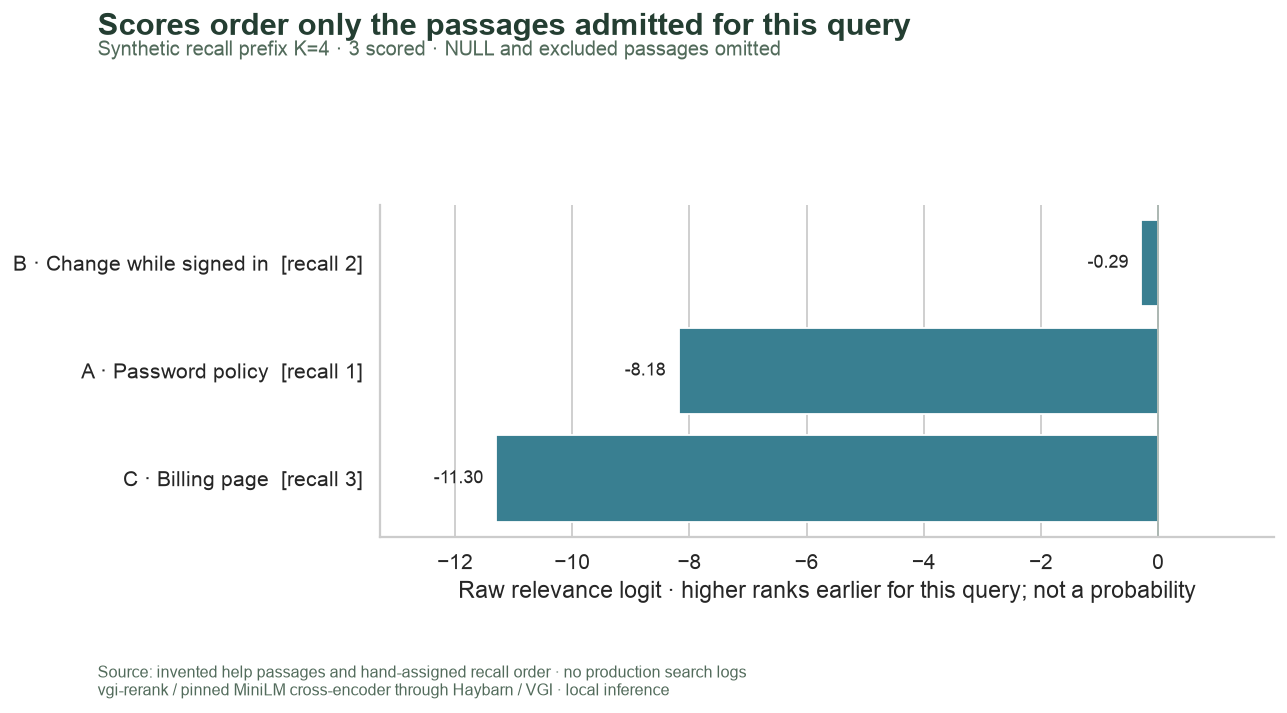

In [9]:
fig, ax = plt.subplots(figsize=(10.5, 5.5))
colors = ["#397d62" if x == "direct answer" else "#397f91" for x in ranking.fixture_role]
ax.barh(range(len(ranking)), ranking.score, color=colors)
ax.set_yticks(range(len(ranking)), [f"{r.id} · {r.title}  [recall {r.recall_rank}]" for r in ranking.itertuples()])
ax.invert_yaxis()
span = max(float(ranking.score.max() - ranking.score.min()), 1)
ax.set_xlim(min(0, float(ranking.score.min())) - span * 0.18, max(0, float(ranking.score.max())) + span * 0.18)
for i, r in enumerate(ranking.itertuples()):
    ax.text(
        r.score + (span * 0.02 if r.score >= 0 else -span * 0.02),
        i,
        f"{r.score:.2f}",
        va="center",
        ha="left" if r.score >= 0 else "right",
        fontsize=10,
    )
ax.axvline(0, color="#aab6b0", linewidth=1)
ax.set_xlabel("Raw relevance logit · higher ranks earlier for this query; not a probability")
ax.grid(axis="y", visible=False)
finish(
    fig,
    f"scores-k{CANDIDATE_LIMIT}",
    "Scores order only the passages admitted for this query",
    f"Synthetic recall prefix K={CANDIDATE_LIMIT} · {len(ranking)} scored · NULL and excluded passages omitted",
)

## Trace the change in rank

The left side keeps the original positions, including gaps caused by unusable text. The right side ranks only scored passages, with a deterministic ID tie-breaker. A rising line means a smaller rank number after reranking. Missing text has no right-hand position; the status table remains the source for those rows. Rank changes are relative to the admitted set, so adding candidates can change a rank without changing a passage’s text.

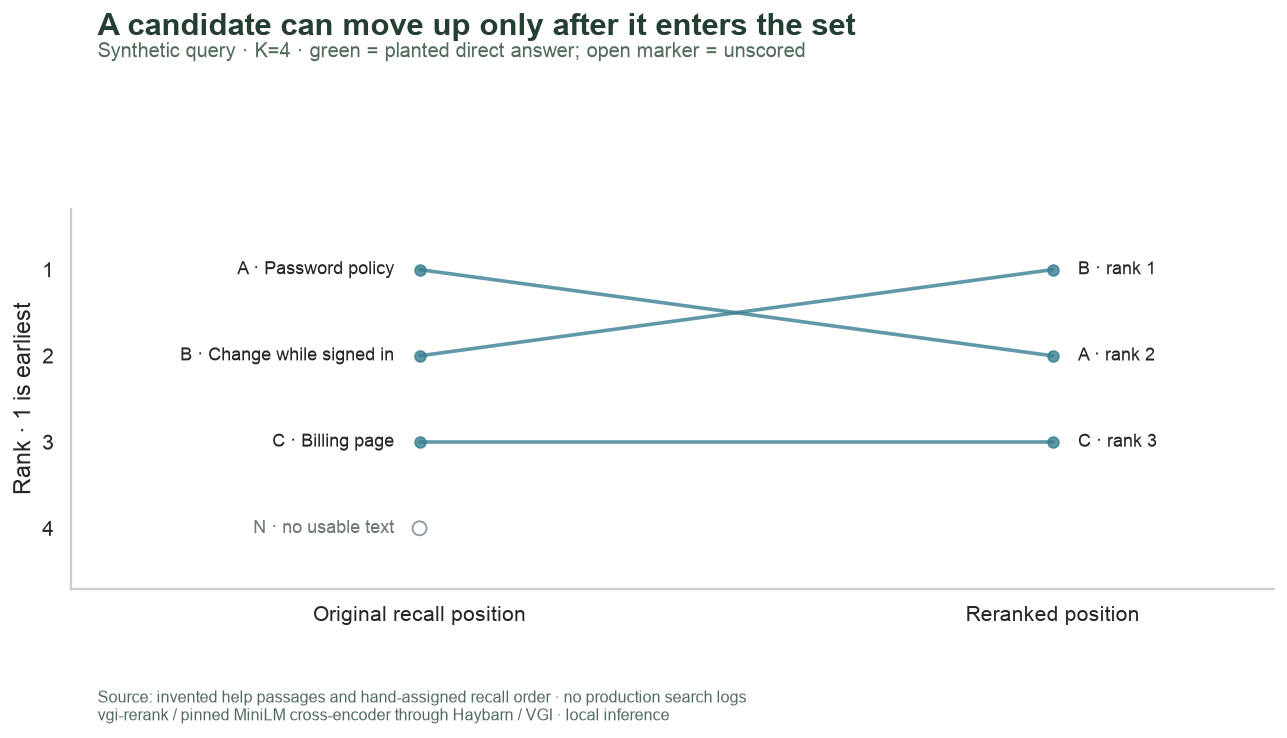

In [10]:
fig, ax = plt.subplots(figsize=(10.5, 5.7))
for r in ranking.itertuples():
    color = "#397d62" if r.fixture_role == "direct answer" else "#397f91"
    ax.plot([0, 1], [r.recall_rank, r.rerank_position], "o-", color=color, alpha=0.8, linewidth=2)
    ax.text(-0.04, r.recall_rank, f"{r.id} · {r.title}", ha="right", va="center", fontsize=10)
    ax.text(1.04, r.rerank_position, f"{r.id} · rank {r.rerank_position}", ha="left", va="center", fontsize=10)
missing = ledger.loc[(ledger.state == "admitted; no usable text")]
for r in missing.itertuples():
    ax.scatter([0], [r.recall_rank], facecolors="none", edgecolors="#8c9b9d", s=60)
    ax.text(-0.04, r.recall_rank, f"{r.id} · no usable text", ha="right", va="center", fontsize=10, color="#6d7777")
ax.set_xlim(-0.55, 1.35)
ax.set_ylim(CANDIDATE_LIMIT + 0.7, 0.3)
ax.set_xticks([0, 1], ["Original recall position", "Reranked position"])
ax.set_yticks(range(1, CANDIDATE_LIMIT + 1))
ax.set_ylabel("Rank · 1 is earliest")
ax.grid(False)
finish(
    fig,
    f"movement-k{CANDIDATE_LIMIT}",
    "A candidate can move up only after it enters the set",
    f"Synthetic query · K={CANDIDATE_LIMIT} · green = planted direct answer; open marker = unscored",
)

In [11]:
%%sql result <<
SELECT id,title,body,score,rerank_position FROM chosen ORDER BY rerank_position;

In [12]:
%%sql summary <<
SELECT (SELECT count(*) FROM admitted) AS admitted_count,
 (SELECT count(*) FROM ranked) AS scored_count,
 (SELECT count(*) FROM scored WHERE score IS NULL) AS null_count,
 (SELECT count(*) FROM chosen) AS chosen_count,
 (SELECT count(*) FROM admitted WHERE fixture_role='direct answer') AS direct_admitted,
 (SELECT count(*) FROM chosen WHERE fixture_role='direct answer') AS direct_chosen;

In [13]:
display(result)
s = summary.iloc[0]
top = result.iloc[0]
answer_state = "is present" if s.direct_admitted else "is absent"
selection_state = "is selected" if s.direct_chosen else "is not selected"
display(
    Markdown(
        f"The budget admits **{int(s.admitted_count)} passages**, of which **{int(s.scored_count)}** "
        f"receive scores. Missing or blank text prevents scoring the other **{int(s.null_count)}**. "
        f"The top result is **{top.id}: {top.title}**. "
        f"The planted direct answer **{answer_state}** in the candidate set and **{selection_state}** in the "
        f"**{int(s.chosen_count)}-passage** output. A high relative rank cannot compensate for a missing answer. "
        "Read the chosen text: topical similarity alone does not establish that it solves the stated task."
    )
)

,id,title,body,score,rerank_position
0,B,Change while signed in,"To change a known password, sign in and open A...",-0.285443,1
1,A,Password policy,Password requirements: use a long unique passw...,-8.184525,2


The budget admits **4 passages**, of which **3** receive scores. Missing or blank text prevents scoring the other **1**. The top result is **B: Change while signed in**. The planted direct answer **is absent** in the candidate set and **is not selected** in the **2-passage** output. A high relative rank cannot compensate for a missing answer. Read the chosen text: topical similarity alone does not establish that it solves the stated task.

## Check the selection boundary and NULL handling

These checks verify the candidate budget, score/rank consistency, identity preservation, model availability and documented NULL behavior. They do not require a particular relevance ranking or logit, which can vary slightly by runtime/platform. Four separate empty/NULL controls exercise both sides of a pair without supplying any additional substantive candidate to the model.

In [14]:
%%sql
CREATE TABLE null_inputs AS SELECT * FROM(VALUES
 (NULL::VARCHAR,'document'),('','document'),('query',NULL::VARCHAR),('query','   ')) AS v(q,d);
CREATE TABLE null_results AS SELECT rerank.main.rerank_score(q,d) AS score FROM null_inputs;

,Count


In [15]:
%%sql checks <<
SELECT 'pool identities and original positions are unique' AS check_name,
 (SELECT count(*)=count(DISTINCT id) AND count(*)=count(DISTINCT recall_rank) FROM candidate_pool) AS passed
UNION ALL SELECT 'candidate budget is applied before scoring',(SELECT count(*)={{CANDIDATE_LIMIT}} FROM admitted)
UNION ALL SELECT 'admitted rows match the original prefix',
 NOT EXISTS(SELECT 1 FROM admitted WHERE recall_rank>{{CANDIDATE_LIMIT}})
UNION ALL SELECT 'scoring preserves candidate identities',
 NOT EXISTS((SELECT id FROM admitted EXCEPT SELECT id FROM scored) UNION ALL(SELECT id FROM scored EXCEPT SELECT id FROM admitted))
UNION ALL SELECT 'NULL score means missing or blank text in this fixture',
 (SELECT bool_and((score IS NULL)=(body IS NULL OR trim(body)='')) FROM scored)
UNION ALL SELECT 'non-NULL scores are finite',(SELECT bool_and(isfinite(score)) FROM ranked)
UNION ALL SELECT 'rank numbers are contiguous',
 (SELECT min(rerank_position)=1 AND max(rerank_position)=count(*) AND count(DISTINCT rerank_position)=count(*) FROM ranked)
UNION ALL SELECT 'scores descend with rank',
 (SELECT bool_and(previous IS NULL OR score<=previous) FROM(SELECT *,lag(score) OVER(ORDER BY rerank_position) AS previous FROM ranked))
UNION ALL SELECT 'chosen rows belong to admitted candidates',NOT EXISTS(SELECT 1 FROM chosen c ANTI JOIN admitted a USING(id))
UNION ALL SELECT 'final count is capped at two usable passages',
 (SELECT count(*)=least(2,(SELECT count(*) FROM ranked)) FROM chosen)
UNION ALL SELECT 'requested model is advertised',
 (SELECT count(*)=1 FROM model_catalog WHERE model='Xenova/ms-marco-MiniLM-L-6-v2')
UNION ALL SELECT 'empty and NULL pair controls produce NULL',(SELECT count(*)=4 AND count(score)=0 FROM null_results);

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
assert connection.execute("SELECT body FROM query").fetchone()[0] == provenance["query"]
display(Markdown(f"**{len(checks)} SQL checks passed**, with input and model-asset provenance verified."))

,check_name,passed
0,pool identities and original positions are unique,True
1,candidate budget is applied before scoring,True
2,admitted rows match the original prefix,True
3,scoring preserves candidate identities,True
4,NULL score means missing or blank text in this...,True
5,non-NULL scores are finite,True
6,rank numbers are contiguous,True
7,scores descend with rank,True
8,chosen rows belong to admitted candidates,True
9,final count is capped at two usable passages,True


**12 SQL checks passed**, with input and model-asset provenance verified.

## Focused experiment: admit the rest of the candidates

Change only **`CANDIDATE_LIMIT` from 4 to 8**, restart and run all. Predict that the planted direct answer D will become available and rank above the merely related password material. Compare the chosen text, the score chart and the count of scored versus unusable passages. The model and query stay fixed.

The experiment demonstrates a candidate-coverage limitation, not a measured improvement in search quality or a recommendation for a universal K. More admitted text means more query–document scoring work; these small runs are not latency benchmarks. Restore **4** for the saved baseline. The README command writes the experiment to a separate copy.

In [17]:
connection.close()
assets.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>